Daniel Agustín Rojas González 22.413.375-8
Tarea 3

In [20]:
import numpy as np

In [21]:
import matplotlib.pyplot as plt

In [24]:
rng = np.random.default_rng(seed=8)

In [25]:
#Ejercicio 1

In [26]:
#Arreglo temporal y flujo normalizado igual a 1
t = np.linspace(0, 10, 500)
flujo = np.ones(500)

In [27]:
#tránsito 1 (t entre 4.5 y 5.0 años con caida de 0.02)
transito_1 = (4.5 <= t) & (t <= 5.0)
flujo[transito_1] -= 0.02

In [30]:
#tránsito 2 (t entre 7.0 y 7.4 años con caida de 0.015)
transito_2 = (t >= 7.0) & (t <= 7.4)
flujo[transito_2] -= 0.015

In [31]:
#ruido gaussiano con desviación estándar = 0.002
ruido_g = rng.normal(loc=0, scale=0.002, size=(500,))
f_ruidoso = flujo + ruido_g

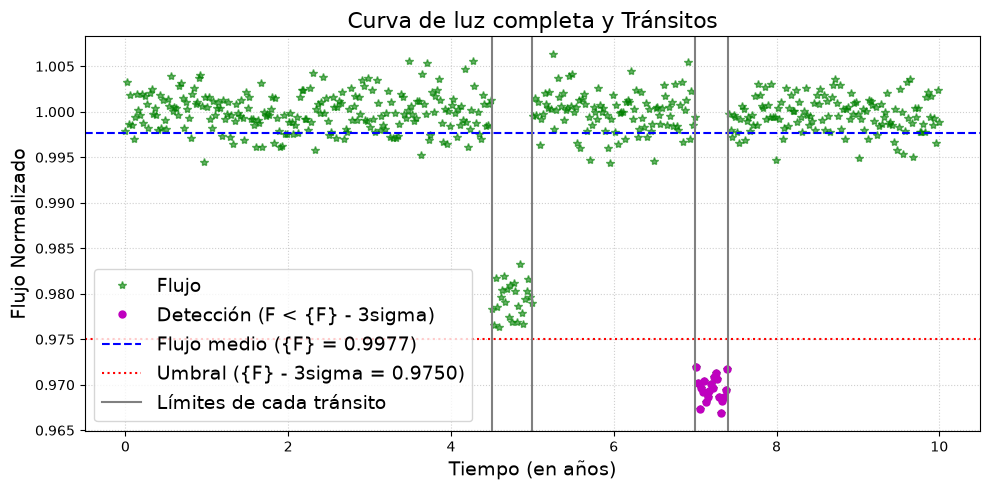

In [32]:
#definir la figura
def graficar_curva(t, flujo):
    f_medio = np.mean(flujo)
    sigma = np.std(flujo)
    umbral = f_medio - 3 * sigma
    mascara_c = flujo < umbral
    
    plt.figure(figsize=(10, 5))
    plt.plot(t, flujo, '*', color='green', alpha=0.6, label='Flujo')
    plt.plot(t[mascara_c], flujo[mascara_c], 'mo', 
             label=r'Detección (F < {F} - 3sigma)', markersize=5)
    plt.axhline(f_medio, color='blue', linestyle='--', linewidth=1.5, 
                label=rf'Flujo medio ({{F}} = {f_medio:.4f})')
    plt.axhline(umbral, color='red', linestyle=':', linewidth=1.5, 
                label=rf'Umbral ({{F}} - 3sigma = {umbral:.4f})')
    plt.axvline(4.5, color='grey', linestyle='-')
    plt.axvline(5.0, color='grey', linestyle='-')
    plt.axvline(7.0, color='grey', linestyle='-')
    plt.axvline(7.4, color='grey', linestyle='-', label='Límites de cada tránsito')
    plt.xlabel('Tiempo (en años)', fontsize=14)
    plt.ylabel('Flujo Normalizado', fontsize=14)
    plt.title('Curva de luz completa y Tránsitos', fontsize=16)
    plt.legend(fontsize=14)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.show()

graficar_curva(t, f_ruidoso)

In [53]:
#Ejercicio 2

In [54]:
N_estrellas = 5
I0 = 100
sigma = 0.5

x0 = rng.uniform(-5, 5, N_estrellas)
y0 = rng.uniform(-5, 5, N_estrellas)

#ejes x e y
x = np.linspace(-5, 5, 500)
y = np.linspace(-5, 5, 500)
X, Y = np.meshgrid(x, y)

In [55]:
#(a) Genere una imagen que contenga cinco estrellas.

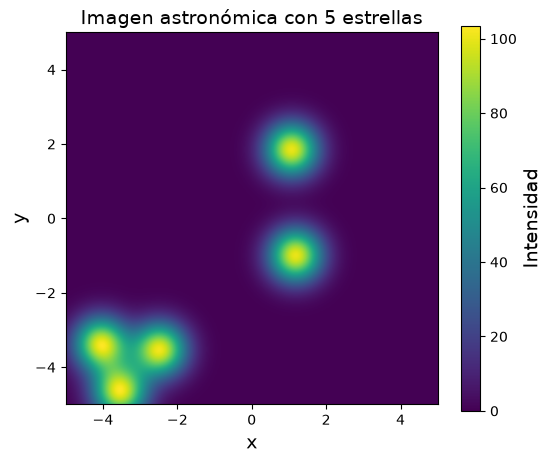

In [56]:
#definir las estrellas y luego sumar 
imagen = (I0 * np.exp(-((X - x0[0])**2 + (Y - y0[0])**2) / (2 * sigma**2)) +
          I0 * np.exp(-((X - x0[1])**2 + (Y - y0[1])**2) / (2 * sigma**2)) +
          I0 * np.exp(-((X - x0[2])**2 + (Y - y0[2])**2) / (2 * sigma**2)) +
          I0 * np.exp(-((X - x0[3])**2 + (Y - y0[3])**2) / (2 * sigma**2)) +
          I0 * np.exp(-((X - x0[4])**2 + (Y - y0[4])**2) / (2 * sigma**2)))

#figura
plt.figure(figsize=(6, 5))
plt.imshow(imagen, origin="lower", extent=[-5, 5, -5, 5])

cbar = plt.colorbar()
cbar.set_label("Intensidad", fontsize=14)

plt.xlabel("x", fontsize=14)
plt.ylabel("y", fontsize=14)
plt.title("Imagen astronómica con 5 estrellas", fontsize=14)
plt.show()

In [57]:
#b)Cree una función que calcule las distancias euclidianas entre los centros de todas las estrellas.

In [58]:
def cal_distancias(x0, y0):
    n = len(x0)
    matriz = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            matriz[i, j] = np.sqrt((x0[i] - x0[j])**2 + (y0[i] - y0[j])**2)
    return matriz

distancias = cal_distancias(x0, y0)
print("Matriz de distancias euclidianas entre los centros de las estrellas:")
print(distancias)

Matriz de distancias euclidianas entre los centros de las estrellas:
[[0.         5.75738989 7.33126853 1.37345335 1.5834642 ]
 [5.75738989 0.         2.85201759 5.98332943 4.45385614]
 [7.33126853 2.85201759 0.         7.98646591 6.45123775]
 [1.37345335 5.98332943 7.98646591 0.         1.55426943]
 [1.5834642  4.45385614 6.45123775 1.55426943 0.        ]]


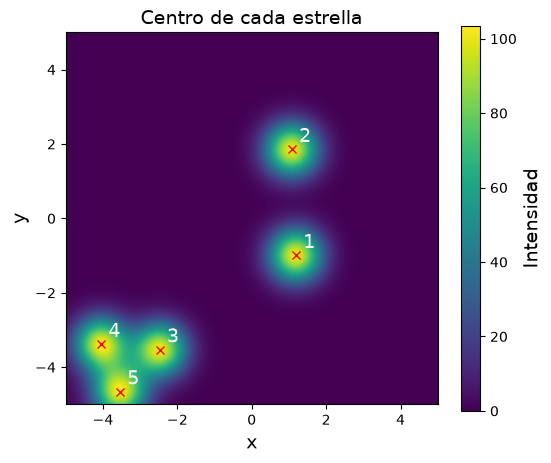

In [60]:
intensidad_estrellas = []
for i in range(N_estrellas):
    idx_x = np.argmin(np.abs(x - x0[i]))
    idx_y = np.argmin(np.abs(y - y0[i]))
    intensidad_estrellas.append(imagen[idx_y, idx_x])

#se busca el orden de mayor a menor intensidad
orden = np.argsort(intensidad_estrellas)

#c)Genere una figura de la imagen astron ́omica en la que se identifique el centro de cada estrella mediante un número.
plt.figure(figsize=(6, 5))
plt.imshow(imagen, origin="lower", extent=[-5, 5, -5, 5])
cbar = plt.colorbar()
cbar.set_label("Intensidad", fontsize=14)

for numero, idx in enumerate(orden, start=1):
    plt.plot(x0[idx], y0[idx], 'rx')
    plt.text(x0[idx] + 0.2, y0[idx] + 0.2, str(numero), color='white', fontsize=14)

plt.xlabel("x", fontsize=14)
plt.ylabel("y", fontsize=14)
plt.title("Centro de cada estrella", fontsize=14)
plt.show()